# GPT vs Llama vs MoE: What Changed in the Decoder Block, and Why

---

Creator: Chung-En Johnny Yu

Content updated: 2026-10-29

Live companion for **M16 — GPT Architecture + Pretraining**. The course notebook `03_architecture_gpt.ipynb` builds GPT-2. Since then the decoder block has **converged** on a recipe almost every open model shares. Following Raschka's GPT→Llama conversion, this notebook changes one component at a time and explains each change as a design decision, then replaces the dense feed-forward layer with a Mixture of Experts.

**Sources** — every section is tagged:

| Tag | Source | License |
|---|---|---|
| 📗 **[GPT→Llama 2]** | Sebastian Raschka, LLMs-from-scratch [`ch05/07_gpt_to_llama/converting-gpt-to-llama2.ipynb`](https://github.com/rasbt/LLMs-from-scratch/blob/main/ch05/07_gpt_to_llama/converting-gpt-to-llama2.ipynb) | Apache-2.0 (code/text) |
| 📗 **[Llama 2→3]** | Raschka, [`converting-llama2-to-llama3.ipynb`](https://github.com/rasbt/LLMs-from-scratch/blob/main/ch05/07_gpt_to_llama/converting-llama2-to-llama3.ipynb) | Apache-2.0 |
| 📗 **[MoE bonus]** | Raschka, [`ch04/07_moe`](https://github.com/rasbt/LLMs-from-scratch/tree/main/ch04/07_moe) — README text, `gpt_with_kv_moe.py`, `memory_estimator_moe.py` (copied into `06-gpt_vs_llama_vs_moe/data/`) | Apache-2.0 |
| 📗 **figures** | from the bonus folders above | not covered by the repo license; copied into `06-gpt_vs_llama_vs_moe/img/` with attribution (see `SOURCE.md`) |
| 🧪 **[Added]** | Written for this companion | — |

CPU only, under a minute; no weights are downloaded (the 7B model is "built" on PyTorch's `meta` device, which allocates no memory).

| Part | Content |
|---|---|
| 1 | The big picture: GPT-2 vs Llama 2 vs Llama 3 |
| 2 | GPT → Llama 2, one component at a time |
| 3 | Llama 2 → Llama 3 |
| 4 | Counting parameters from a config |
| 5 | Mixture of Experts |
| 6 | Interview-style check questions |

---

In [1]:
import inspect, math, os, subprocess, sys, urllib.request
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

# 🧪 [Added] fetch Raschka's MoE scripts: local copy -> this repo -> original repo
local_dir = os.path.join("06-gpt_vs_llama_vs_moe", "data")
if os.path.isdir(local_dir):
    sys.path.insert(0, local_dir); SCRIPT_DIR = local_dir
else:
    SCRIPT_DIR = "."
    for name in ["gpt_with_kv_moe.py", "memory_estimator_moe.py"]:
        if os.path.exists(name):
            continue
        for url in [f"https://raw.githubusercontent.com/chungenyu6/ai-learning-notebooks/main/02-LLM/live/06-gpt_vs_llama_vs_moe/data/{name}",
                    f"https://raw.githubusercontent.com/rasbt/LLMs-from-scratch/main/ch04/07_moe/{name}"]:
            try:
                urllib.request.urlretrieve(url, name); break
            except Exception as e:
                print("could not download", url, e)
try:
    import tiktoken  # noqa: F401  (gpt_with_kv_moe imports it)
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "tiktoken"])
import gpt_with_kv_moe
print("torch", torch.__version__)

torch 2.13.0


## 1. The big picture

📗 *[GPT→Llama 2] figure; 🧪 [Added] comparison diagram and table*

<img src="https://github.com/chungenyu6/ai-learning-notebooks/blob/main/02-LLM/live/06-gpt_vs_llama_vs_moe/img/gpt2-to-llama2-llama3.webp?raw=true" width="800px">

*Figure: GPT-2 XL 1.5B → Llama 2 7B → Llama 3 8B, with the changed components highlighted. Source: Raschka, LLMs-from-scratch, GPT-to-Llama bonus (original image `bonus/gpt-to-llama/gpt2-to-llama2-llama3.webp`).*

🧪 All three are **decoder-only, pre-norm, residual** stacks trained with next-token prediction; the skeleton
$h \leftarrow h + \operatorname{Attention}(\operatorname{Norm}(h))$, $h \leftarrow h + \operatorname{FFN}(\operatorname{Norm}(h))$ is identical. What differs is the contents of each box. The diagram below adds the MoE variant (orange = changed vs GPT-2, purple = MoE-specific):

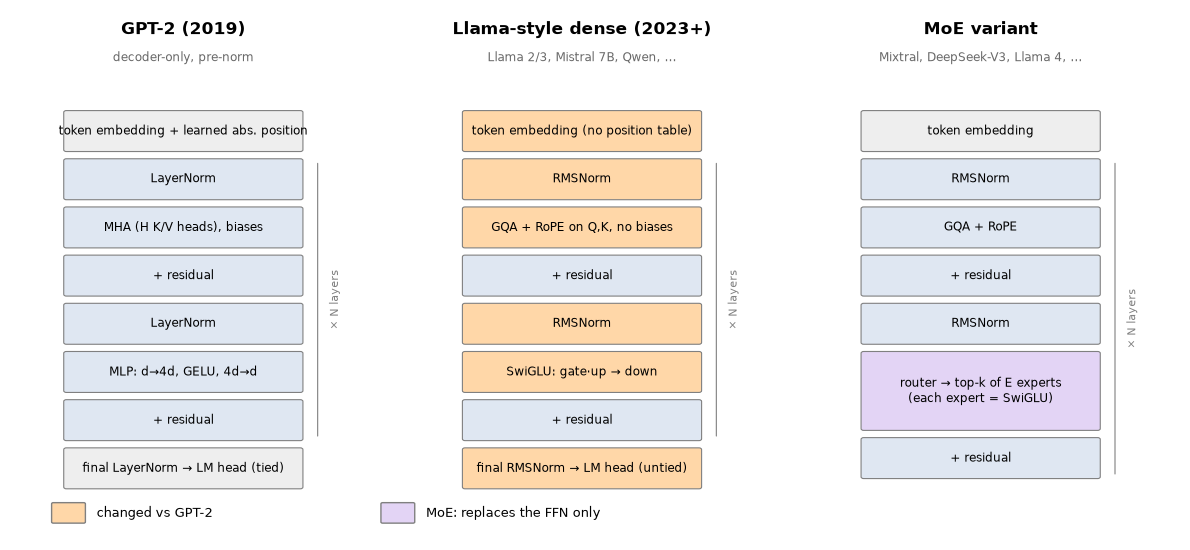

In [2]:
# 🧪 [Added]
def draw_stack(ax, x, title, boxes, subtitle):
    ax.text(x, 10.6, title, ha="center", fontsize=12, weight="bold")
    ax.text(x, 10.15, subtitle, ha="center", fontsize=8.5, color="dimgray")
    y, edges = 9.3, []
    for label, kind in boxes:
        color = {"same": "#dfe7f2", "changed": "#ffd7a8", "moe": "#e3d4f5", "io": "#eeeeee"}[kind]
        h = 0.62 if kind != "moe" else 1.25
        ax.add_patch(FancyBboxPatch((x - 1.35, y - h), 2.7, h, boxstyle="round,pad=0.03", fc=color, ec="gray", lw=0.8))
        ax.text(x, y - h / 2, label, ha="center", va="center", fontsize=8.5)
        edges.append((y, y - h))
        y -= h + 0.18
    top, bottom = edges[1][0], edges[6][1]                 # boxes 1..6 repeat per layer
    ax.annotate("", xy=(x + 1.55, bottom), xytext=(x + 1.55, top), arrowprops=dict(arrowstyle="-", color="gray", lw=0.8))
    ax.text(x + 1.68, (top + bottom) / 2, "× N layers", rotation=90, va="center", fontsize=8, color="gray")

fig, ax = plt.subplots(figsize=(12, 5.6))
ax.set_xlim(0, 13.5); ax.set_ylim(2.2, 11); ax.axis("off")
draw_stack(ax, 2.0, "GPT-2 (2019)", [
    ("token embedding + learned abs. position", "io"), ("LayerNorm", "same"), ("MHA (H K/V heads), biases", "same"),
    ("+ residual", "same"), ("LayerNorm", "same"), ("MLP: d→4d, GELU, 4d→d", "same"), ("+ residual", "same"),
    ("final LayerNorm → LM head (tied)", "io")], "decoder-only, pre-norm")
draw_stack(ax, 6.6, "Llama-style dense (2023+)", [
    ("token embedding (no position table)", "changed"), ("RMSNorm", "changed"), ("GQA + RoPE on Q,K, no biases", "changed"),
    ("+ residual", "same"), ("RMSNorm", "changed"), ("SwiGLU: gate·up → down", "changed"), ("+ residual", "same"),
    ("final RMSNorm → LM head (untied)", "changed")], "Llama 2/3, Mistral 7B, Qwen, …")
draw_stack(ax, 11.2, "MoE variant", [
    ("token embedding", "io"), ("RMSNorm", "same"), ("GQA + RoPE", "same"), ("+ residual", "same"), ("RMSNorm", "same"),
    ("router → top-k of E experts\n(each expert = SwiGLU)", "moe"), ("+ residual", "same")], "Mixtral, DeepSeek-V3, Llama 4, …")
for c, x0, lab in [("#ffd7a8", 0.5, "changed vs GPT-2"), ("#e3d4f5", 4.3, "MoE: replaces the FFN only")]:
    ax.add_patch(FancyBboxPatch((x0, 2.5), 0.35, 0.3, boxstyle="round,pad=0.02", fc=c, ec="gray"))
    ax.text(x0 + 0.5, 2.65, lab, va="center", fontsize=9)
plt.tight_layout(); plt.show()

| Component | GPT-2 | Llama-style dense | Why the change |
|---|---|---|---|
| Position | learned absolute table at the input | **RoPE** on Q and K in every layer | relative positions; no hard max length; context extension |
| Norm | LayerNorm (mean + variance, with bias) | **RMSNorm** (scale only) | cheaper, equally stable in practice |
| Attention | MHA | **GQA** (Llama 2 70B, all Llama 3) | smaller KV cache → faster, cheaper decoding |
| FFN | $W_2\,\mathrm{GELU}(W_1x)$, hidden $4d$ | **SwiGLU** $W_3(\mathrm{SiLU}(W_1x)\odot W_2x)$ | gating gives better quality per parameter |
| Biases / dropout | yes | **none** | fewer parameters, better stability at scale; large pretraining runs rarely overfit |
| Embeddings | input and output tied | untied | output layer can specialize |
| Vocabulary | 50,257 | 32k (Llama 2) → 128k (Llama 3) | shorter sequences for code and many languages |

**MoE is orthogonal to this list.** It keeps the same attention and replaces the dense FFN with experts and a router. Llama 2 and 3 are dense; Llama 4, Mixtral and DeepSeek-V3 are MoE.

## 2. GPT → Llama 2, one component at a time

### 2.1 Replace LayerNorm with RMSNorm

📗 *[GPT→Llama 2] §1.1 text and code; 🧪 [Added] pre-norm note*

- LayerNorm normalizes inputs using mean and variance, while RMSNorm uses only the root mean square, which improves computational efficiency. With input $x$, a trainable vector $\gamma$ and a small constant $\epsilon$:

$$y_i = \frac{x_i}{\text{RMS}(x)} \gamma_i, \quad \text{where} \quad \text{RMS}(x) = \sqrt{\epsilon + \frac{1}{n} \sum x_i^2}$$

- See [Root Mean Square Layer Normalization (2019)](https://arxiv.org/abs/1910.07467).

In [3]:
# Source: Raschka, LLMs-from-scratch, converting-gpt-to-llama2.ipynb (Apache-2.0)
import torch
import torch.nn as nn


#####################################
# Chapter 4
#####################################

# class LayerNorm(nn.Module):
#     def __init__(self, emb_dim):
#         super().__init__()
#         self.eps = 1e-5
#         self.scale = nn.Parameter(torch.ones(emb_dim))
#         self.shift = nn.Parameter(torch.zeros(emb_dim))

#     def forward(self, x):
#         mean = x.mean(dim=-1, keepdim=True)
#         var = x.var(dim=-1, keepdim=True, unbiased=False)
#         norm_x = (x - mean) / torch.sqrt(var + self.eps)
#         return self.scale * norm_x + self.shift


class RMSNorm(nn.Module):
    def __init__(self, emb_dim, eps=1e-5):
        super().__init__()
        self.eps = eps
        self.emb_dim = emb_dim
        self.weight = nn.Parameter(torch.ones(emb_dim)).float()

    def forward(self, x):
        means = x.pow(2).mean(dim=-1, keepdim=True)
        x_normed = x * torch.rsqrt(means + self.eps)
        return (x_normed * self.weight).to(dtype=x.dtype)

In [4]:
# Source: Raschka, LLMs-from-scratch, converting-gpt-to-llama2.ipynb (Apache-2.0)
torch.manual_seed(123)

example_batch = torch.randn(2, 3, 4)

rms_norm = RMSNorm(emb_dim=example_batch.shape[-1])
rmsnorm_pytorch = torch.nn.RMSNorm(example_batch.shape[-1], eps=1e-5)

assert torch.allclose(rms_norm(example_batch), rmsnorm_pytorch(example_batch))
print("matches torch.nn.RMSNorm ✓")

matches torch.nn.RMSNorm ✓


🧪 Both GPT-2 and Llama use **pre-norm** (the norm inside the residual branch). The original 2017 Transformer used post-norm, $\mathrm{Norm}(x+\mathrm{sublayer}(x))$, which needs learning-rate warm-up and is harder to train deep; pre-norm keeps an un-normalized identity path through the whole stack, so gradients flow.

### 2.2 Replace GELU with SiLU

📗 *[GPT→Llama 2] §1.2 text and code; 🧪 [Added] plot*

- Llama uses the SiLU activation function (instead of GELU), also known as Swish:

$$\text{silu}(x) = x \cdot \sigma(x), \quad \text{where} \quad \sigma(x) \text{ is the logistic sigmoid.}$$

- See [Sigmoid-Weighted Linear Units for Neural Network Function Approximation in Reinforcement Learning (2017)](https://arxiv.org/abs/1702.03118).

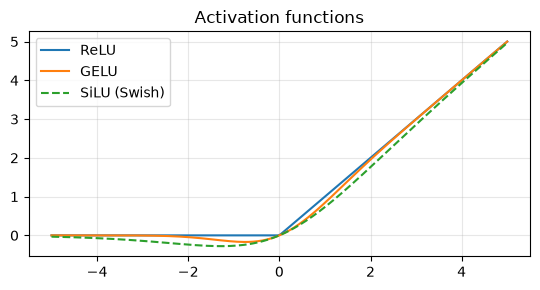

In [5]:
# Source: Raschka, LLMs-from-scratch, converting-gpt-to-llama2.ipynb (Apache-2.0)
#####################################
# Chapter 4
#####################################

# class GELU(nn.Module):
#     def __init__(self):
#         super().__init__()

#     def forward(self, x):
#         return 0.5 * x * (1 + torch.tanh(
#             torch.sqrt(torch.tensor(2.0 / torch.pi)) *
#             (x + 0.044715 * torch.pow(x, 3))
#         ))


class SiLU(nn.Module):
    def __init__(self):
        super(SiLU, self).__init__()

    def forward(self, x):
        return x * torch.sigmoid(x)

silu = SiLU()

assert torch.allclose(silu(example_batch), torch.nn.functional.silu(example_batch))

# 🧪 [Added]
z = torch.linspace(-5, 5, 200)
plt.figure(figsize=(5.5, 3))
plt.plot(z, F.relu(z), label="ReLU"); plt.plot(z, F.gelu(z), label="GELU"); plt.plot(z, F.silu(z), "--", label="SiLU (Swish)")
plt.legend(); plt.grid(alpha=.3); plt.title("Activation functions"); plt.tight_layout(); plt.show()

### 2.3 Update the FeedForward module: SwiGLU

📗 *[GPT→Llama 2] §1.3 text and code; 🧪 [Added] parameter note*

- Llama uses a "Gated Linear Unit" (GLU) variant of SiLU called SwiGLU, which results in a slightly differently structured `FeedForward` module:

$$\text{SwiGLU}(x) = \text{SiLU}(\text{Linear}_1(x)) * (\text{Linear}_2(x))$$

- $\text{Linear}_1$ and $\text{Linear}_2$ are two linear layers, $*$ is element-wise multiplication, and a third linear layer $\text{Linear}_3$ is applied after this gated activation. See [GLU Variants Improve Transformer (2020)](https://arxiv.org/abs/2002.05202).
- A `dtype=cfg["dtype"]` setting allows instantiating the model directly in lower precision; `bias=False` because Llama uses no bias units.

In [6]:
# Source: Raschka, LLMs-from-scratch, converting-gpt-to-llama2.ipynb (Apache-2.0)
class FeedForward(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.fc1 = nn.Linear(cfg["emb_dim"], cfg["hidden_dim"], dtype=cfg["dtype"], bias=False)
        self.fc2 = nn.Linear(cfg["emb_dim"], cfg["hidden_dim"], dtype=cfg["dtype"], bias=False)
        self.fc3 = nn.Linear(cfg["hidden_dim"], cfg["emb_dim"], dtype=cfg["dtype"], bias=False)
        self.silu = SiLU()

    def forward(self, x):
        x_fc1 = self.fc1(x)
        x_fc2 = self.fc2(x)
        x = self.silu(x_fc1) * x_fc2
        return self.fc3(x)

🧪 SwiGLU has **three** matrices instead of two, so to keep the parameter count of a $4d$-wide GELU MLP the hidden size shrinks to $\tfrac83 d$: $3\cdot d\cdot\tfrac83 d = 8d^2 = 2\cdot d\cdot 4d$. Llama 2 7B uses 11,008 ≈ $2.7d$; Llama 3 8B uses 14,336 = $3.5d$.

### 2.4 RoPE inside multi-head attention

📗 *[GPT→Llama 2] §1.4–1.5 code (explained in companion `04_positional_encoding_rope`)*

GPT applies positional embeddings to the inputs; Llama rotates the queries and keys inside attention. The same functions and attention class as in notebook 04:

In [7]:
# Source: Raschka, LLMs-from-scratch, converting-gpt-to-llama2.ipynb (Apache-2.0)
def precompute_rope_params(head_dim, theta_base=10_000, context_length=4096):
    assert head_dim % 2 == 0, "Embedding dimension must be even"

    # Compute the inverse frequencies
    inv_freq = 1.0 / (theta_base ** (torch.arange(0, head_dim, 2)[: (head_dim // 2)].float() / head_dim))

    # Generate position indices
    positions = torch.arange(context_length)

    # Compute the angles
    angles = positions.unsqueeze(1) * inv_freq.unsqueeze(0)  # Shape: (context_length, head_dim // 2)

    # Expand angles to match the head_dim
    angles = torch.cat([angles, angles], dim=1)  # Shape: (context_length, head_dim)

    # Precompute sine and cosine
    cos = torch.cos(angles)
    sin = torch.sin(angles)

    return cos, sin

def compute_rope(x, cos, sin):
    # x: (batch_size, num_heads, seq_len, head_dim)
    batch_size, num_heads, seq_len, head_dim = x.shape
    assert head_dim % 2 == 0, "Head dimension must be even"

    # Split x into first half and second half
    x1 = x[..., : head_dim // 2]  # First half
    x2 = x[..., head_dim // 2 :]  # Second half

    # Adjust sin and cos shapes
    cos = cos[:seq_len, :].unsqueeze(0).unsqueeze(0)  # Shape: (1, 1, seq_len, head_dim)
    sin = sin[:seq_len, :].unsqueeze(0).unsqueeze(0)

    # Apply the rotary transformation
    rotated = torch.cat((-x2, x1), dim=-1)
    x_rotated = (x * cos) + (rotated * sin)

    return x_rotated.to(dtype=x.dtype)


#####################################
# Chapter 3
#####################################
class MultiHeadAttention(nn.Module):
    def __init__(self, d_in, d_out, context_length, num_heads, dtype=None):  # ,dropout, num_heads, qkv_bias=False):
        super().__init__()
        assert d_out % num_heads == 0, "d_out must be divisible by n_heads"

        self.d_out = d_out
        self.num_heads = num_heads
        self.head_dim = d_out // num_heads  # Reduce the projection dim to match desired output dim

        ################################### NEW ###################################
        # Set bias=False and dtype=dtype for all linear layers below
        ###########################################################################
        self.W_query = nn.Linear(d_in, d_out, bias=False, dtype=dtype)
        self.W_key = nn.Linear(d_in, d_out, bias=False, dtype=dtype)
        self.W_value = nn.Linear(d_in, d_out, bias=False, dtype=dtype)
        self.out_proj = nn.Linear(d_out, d_out, bias=False, dtype=dtype)  # Linear layer to combine head outputs
        # self.dropout = nn.Dropout(dropout)
        self.register_buffer("mask", torch.triu(torch.ones(context_length, context_length), diagonal=1))

        ################################### NEW ###################################
        cos, sin = precompute_rope_params(head_dim=self.head_dim, context_length=context_length)
        self.register_buffer("cos", cos)
        self.register_buffer("sin", sin)
        ###########################################################################


    def forward(self, x):

        b, num_tokens, d_in = x.shape

        keys = self.W_key(x)  # Shape: (b, num_tokens, d_out)
        queries = self.W_query(x)
        values = self.W_value(x)

        # We implicitly split the matrix by adding a `num_heads` dimension
        # Unroll last dim: (b, num_tokens, d_out) -> (b, num_tokens, num_heads, head_dim)
        keys = keys.view(b, num_tokens, self.num_heads, self.head_dim)
        values = values.view(b, num_tokens, self.num_heads, self.head_dim)
        queries = queries.view(b, num_tokens, self.num_heads, self.head_dim)

        # Transpose: (b, num_tokens, num_heads, head_dim) -> (b, num_heads, num_tokens, head_dim)
        keys = keys.transpose(1, 2)
        queries = queries.transpose(1, 2)
        values = values.transpose(1, 2)

        ################################### NEW ###################################
        keys = compute_rope(keys, self.cos, self.sin)
        queries = compute_rope(queries, self.cos, self.sin)
        ###########################################################################

        # Compute scaled dot-product attention (aka self-attention) with a causal mask
        attn_scores = queries @ keys.transpose(2, 3)  # Dot product for each head

        # Original mask truncated to the number of tokens and converted to boolean
        mask_bool = self.mask.bool()[:num_tokens, :num_tokens]

        # Use the mask to fill attention scores
        attn_scores.masked_fill_(mask_bool, -torch.inf)

        attn_weights = torch.softmax(attn_scores / keys.shape[-1]**0.5, dim=-1)
        # attn_weights = self.dropout(attn_weights)

        # Shape: (b, num_tokens, num_heads, head_dim)
        context_vec = (attn_weights @ values).transpose(1, 2)

        # Combine heads, where self.d_out = self.num_heads * self.head_dim
        context_vec = context_vec.reshape(b, num_tokens, self.d_out)
        context_vec = self.out_proj(context_vec)  # optional projection

        return context_vec

### 2.5 Update the TransformerBlock and the model class

📗 *[GPT→Llama 2] §1.6–1.7 text and code*

- The `TransformerBlock`: replace LayerNorm with RMSNorm, remove dropout, remove the `qkv_bias` setting, add the `dtype` setting.
- The model class: remove the absolute positional embeddings (RoPE replaces them), replace LayerNorm with RMSNorm, remove dropout, add the dtype setting.

In [8]:
# Source: Raschka, LLMs-from-scratch, converting-gpt-to-llama2.ipynb (Apache-2.0)
class TransformerBlock(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.att = MultiHeadAttention(
            d_in=cfg["emb_dim"],
            d_out=cfg["emb_dim"],
            context_length=cfg["context_length"],
            num_heads=cfg["n_heads"],
            dtype=cfg["dtype"]  # NEW
            # dropout=cfg["drop_rate"],
            # qkv_bias=cfg["qkv_bias"]
        )
        self.ff = FeedForward(cfg)

        ################################### NEW ###################################
        # self.norm1 = LayerNorm(cfg["emb_dim"])
        # self.norm2 = LayerNorm(cfg["emb_dim"])
        self.norm1 = RMSNorm(cfg["emb_dim"])
        self.norm2 = RMSNorm(cfg["emb_dim"])
        ###########################################################################

        # self.drop_shortcut = nn.Dropout(cfg["drop_rate"])

    def forward(self, x):
        # Shortcut connection for attention block
        shortcut = x
        x = self.norm1(x)
        x = self.att(x)   # Shape [batch_size, num_tokens, emb_size]
        # x = self.drop_shortcut(x)
        x = x + shortcut  # Add the original input back

        # Shortcut connection for feed-forward block
        shortcut = x
        x = self.norm2(x)
        x = self.ff(x)
        # x = self.drop_shortcut(x)
        x = x + shortcut  # Add the original input back

        return x


# class GPTModel(nn.Module):
class Llama2Model(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.tok_emb = nn.Embedding(cfg["vocab_size"], cfg["emb_dim"], dtype=cfg["dtype"])
        # self.pos_emb = nn.Embedding(cfg["context_length"], cfg["emb_dim"])
        # self.drop_emb = nn.Dropout(cfg["drop_rate"])

        self.trf_blocks = nn.Sequential(
            *[TransformerBlock(cfg) for _ in range(cfg["n_layers"])])

        ################################### NEW ###################################
        # self.final_norm = LayerNorm(cfg["emb_dim"])
        self.final_norm = RMSNorm(cfg["emb_dim"])
        ###########################################################################
        self.out_head = nn.Linear(cfg["emb_dim"], cfg["vocab_size"], bias=False, dtype=cfg["dtype"])

    def forward(self, in_idx):
        # batch_size, seq_len = in_idx.shape
        tok_embeds = self.tok_emb(in_idx)
        # pos_embeds = self.pos_emb(torch.arange(seq_len, device=in_idx.device))
        x = tok_embeds  # + pos_embeds  # Shape [batch_size, num_tokens, emb_size]
        # x = self.drop_emb(x)
        x = self.trf_blocks(x)
        x = self.final_norm(x)
        logits = self.out_head(x)
        return logits

### 2.6 Initialize: the 7B configuration

📗 *[GPT→Llama 2] §2 code; 🧪 [Added] meta-device trick and causality test*

Instantiating the real 7B model needs tens of GB of memory. 🧪 On PyTorch's `meta` device, tensors have shapes but no storage, so we can build it and count parameters instantly:

In [9]:
# Source: Raschka, LLMs-from-scratch, converting-gpt-to-llama2.ipynb (Apache-2.0)
LLAMA2_CONFIG_7B = {
    "vocab_size": 32000,     # Vocabulary size
    "context_length": 4096,  # Context length
    "emb_dim": 4096,         # Embedding dimension
    "n_heads": 32,           # Number of attention heads
    "n_layers": 32,          # Number of layers
    "hidden_dim": 11008,     # NEW: Size of the intermediate dimension in FeedForward
    "dtype": torch.bfloat16  # NEW: Lower-precision dtype to reduce memory usage
}

# 🧪 [Added]
with torch.device("meta"):
    model_7b = Llama2Model(LLAMA2_CONFIG_7B)
total_params = sum(p.numel() for p in model_7b.parameters())
print(f"Total number of parameters: {total_params:,}")
print(f"bfloat16 weights: {total_params * 2 / 1e9:.2f} GB")

Total number of parameters: 6,738,415,616
bfloat16 weights: 13.48 GB


📗 This matches Raschka's notebook: **6,738,415,616 parameters** (the "7B" model). Raschka's memory helper reports 26.17 GB in bfloat16 because it counts parameters **plus gradients** (a training estimate); the weights alone are the 13.48 GB printed above. 🧪 A tiny configuration with the same code runs on CPU; it must be causal like any decoder:

In [10]:
# 🧪 [Added]
TINY = dict(LLAMA2_CONFIG_7B, vocab_size=1000, context_length=64, emb_dim=64, n_heads=4, n_layers=2,
            hidden_dim=172, dtype=torch.float32)
torch.manual_seed(0)
tiny = Llama2Model(TINY).eval()
ids = torch.randint(0, 1000, (2, 10))
ids2 = ids.clone(); ids2[:, 7] = (ids2[:, 7] + 1) % 1000
with torch.no_grad():
    assert torch.allclose(tiny(ids)[:, :7], tiny(ids2)[:, :7], atol=1e-5)
print("logits", tuple(tiny(ids).shape), "| editing token 7 leaves positions 0-6 unchanged ✓")

logits (2, 10, 1000) | editing token 7 leaves positions 0-6 unchanged ✓


## 3. Llama 2 → Llama 3

📗 *[Llama 2→3] text and config; 🧪 [Added] table*

Raschka's follow-up notebook converts Llama 2 to Llama 3 with a few targeted changes:

- **Grouped-query attention** replaces MHA: queries keep one head each, but keys and values are shared among groups of heads, reducing parameters and KV-cache size without significantly reducing modeling performance (details in companion `03_gqa_kv_cache`).
- **RoPE**: context 8,192 (vs 4,096) and RoPE base 500,000 (vs 10,000); Llama 3.1 adds frequency scaling for 128k context (companion `04`).
- **Tokenizer**: a 128,256-token `tiktoken`-based vocabulary instead of Llama 2's 32,000-token SentencePiece.
- **Larger FFN**: hidden size 14,336.

In [11]:
# Source: Raschka, LLMs-from-scratch, converting-llama2-to-llama3.ipynb (Apache-2.0)
LLAMA3_CONFIG_8B = {
    "vocab_size": 128_256,   # NEW: Larger vocabulary size
    "context_length": 8192,  # NEW: Larger context length
    "emb_dim": 4096,         # Embedding dimension
    "n_heads": 32,           # Number of attention heads
    "n_layers": 32,          # Number of layers
    "hidden_dim": 14_336,    # NEW: Larger size of the intermediate dimension in FeedForward
    "n_kv_groups": 8,        # NEW: Key-Value groups for grouped-query attention
    "rope_base": 500_000.0,  # NEW: The base in RoPE's "theta" was increased to 500_000
    "rope_freq": None,       # NEW: Additional configuration for adjusting the RoPE frequencies
    "dtype": torch.bfloat16  # Lower-precision dtype to reduce memory usage
}

## 4. Count the parameters from a config

🧪 *[Added]*

A classic interview exercise: *"Here is a config — roughly how many parameters?"* Closed-form counts, checked against the numbers above:

In [12]:
# 🧪 [Added]
def gpt2_params(V, ctx, d, L):
    emb = V * d + ctx * d                          # token + position tables (output layer tied)
    attn = d * 3 * d + 3 * d + d * d + d            # qkv + proj, with biases
    mlp = d * 4 * d + 4 * d + 4 * d * d + d
    return emb + L * (attn + mlp + 4 * d) + 2 * d   # two LayerNorms per block + final

def llama_params(V, d, L, H, H_kv, ffn):
    dh = d // H
    attn = d * H * dh + 2 * d * H_kv * dh + H * dh * d
    return 2 * V * d + L * (attn + 3 * d * ffn + 2 * d) + d   # untied embedding + head, 2 RMSNorms, final norm

p_gpt2 = gpt2_params(V=50257, ctx=1024, d=768, L=12)
p_l2 = llama_params(V=32000, d=4096, L=32, H=32, H_kv=32, ffn=11008)
p_l3 = llama_params(V=128256, d=4096, L=32, H=32, H_kv=8, ffn=14336)
print(f"GPT-2 small : {p_gpt2:,}   (published ≈124M)")
print(f"Llama 2 7B  : {p_l2:,}   (meta-device count above: {total_params:,})")
print(f"Llama 3 8B  : {p_l3:,}   (published ≈8.03B)")
assert p_l2 == total_params

parts = {"attention (GQA)": 32 * (2 * 4096**2 + 2 * 4096 * 1024), "FFN (SwiGLU)": 32 * 3 * 4096 * 14336,
         "embeddings + LM head": 2 * 128256 * 4096}
for k, v in parts.items():
    print(f"  Llama 3 8B {k:22s} {v / 1e9:5.2f}B  ({100 * v / p_l3:4.1f}%)")

GPT-2 small : 124,439,808   (published ≈124M)
Llama 2 7B  : 6,738,415,616   (meta-device count above: 6,738,415,616)
Llama 3 8B  : 8,030,261,248   (published ≈8.03B)
  Llama 3 8B attention (GQA)         1.34B  (16.7%)
  Llama 3 8B FFN (SwiGLU)            5.64B  (70.2%)
  Llama 3 8B embeddings + LM head    1.05B  (13.1%)


**Take-away:** about 70% of a dense LLM's parameters sit in the **FFN** — exactly the part MoE makes sparse. Rule of thumb: a dense model has about $12\,L\,d^2$ non-embedding parameters (attention ≈ $4d^2$, FFN ≈ $8d^2$ per layer).

## 5. Mixture of Experts

📗 *[MoE bonus] text, figures and code; 🧪 [Added] load-balancing demo and totals*

The core idea in MoE is to replace each feed-forward module in a transformer block with multiple expert layers, each of which is also a feed-forward module:

<img src="https://github.com/chungenyu6/ai-learning-notebooks/blob/main/02-LLM/live/06-gpt_vs_llama_vs_moe/img/moe-1.webp?raw=true" width="700px">

*Figure: a dense architecture vs DeepSeek-V3's MoE, where a router selects experts. Source: Raschka, LLMs-from-scratch, MoE bonus (original image `bonus/moe-memory/1.webp`).*

- The feed-forward block typically contains a large share of the model's parameters, and it is repeated in every transformer block (61 times in DeepSeek-V3). Replacing one feed-forward block with many substantially increases the **total** parameter count.
- The key trick: not all experts are used for every token. A **router** selects a small subset per token, so MoE modules are called *sparse*, in contrast to *dense* modules. The large total capacity lets the model take up more knowledge during training, while sparsity keeps inference efficient.
- DeepSeek-V3 has 256 experts per MoE module and 671B parameters in total, yet only 9 experts are active per token (1 **shared expert** plus 8 routed), i.e., about 37B parameters per inference step.

<img src="https://github.com/chungenyu6/ai-learning-notebooks/blob/main/02-LLM/live/06-gpt_vs_llama_vs_moe/img/moe-3.webp?raw=true" width="550px">

*Figure: conventional top-2 routing → fine-grained experts → a shared expert that is always active. Source: annotated figure from the DeepSeekMoE paper (arXiv:2401.06066), via Raschka's MoE bonus (original image `bonus/moe-memory/3.webp`).*

- A shared expert (DeepSpeed-MoE 2022, DeepSeekMoE 2024) boosts performance: common patterns need not be learned by many experts, leaving them more room to specialize.

Raschka's `MoEFeedForward`: a linear **gate** (router) scores the experts, `topk` keeps the best `num_experts_per_tok`, a softmax over those scores gives the mixing weights, and each selected expert (a SwiGLU FFN) processes only its tokens:

In [13]:
# Source: Raschka, LLMs-from-scratch, ch04/07_moe/gpt_with_kv_moe.py (Apache-2.0)
MoEFeedForward = gpt_with_kv_moe.MoEFeedForward
print(inspect.getsource(MoEFeedForward))

class MoEFeedForward(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.num_experts_per_tok = cfg["num_experts_per_tok"]
        self.num_experts = cfg["num_experts"]
        self.emb_dim = cfg["emb_dim"]

        self.gate = nn.Linear(cfg["emb_dim"], cfg["num_experts"], bias=False)
        self.fc1 = nn.ModuleList(
            [
                nn.Linear(cfg["emb_dim"], cfg["hidden_dim"], bias=False)
                for _ in range(self.num_experts)
            ]
        )
        self.fc2 = nn.ModuleList(
            [
                nn.Linear(cfg["emb_dim"], cfg["hidden_dim"], bias=False)
                for _ in range(self.num_experts)
            ]
        )
        self.fc3 = nn.ModuleList(
            [
                nn.Linear(cfg["hidden_dim"], cfg["emb_dim"], bias=False)
                for _ in range(self.num_experts)
            ]
        )

    def forward(self, x):
        # x: (batch, seq_len, emb_dim)
        scores = self.gate(x)  # (b, s

In [14]:
# 🧪 [Added] use it as a drop-in FFN
moe_cfg = {"emb_dim": 64, "hidden_dim": 32, "num_experts": 8, "num_experts_per_tok": 2}
torch.manual_seed(0)
moe = MoEFeedForward(moe_cfg)
x = torch.randn(4, 32, 64)
y = moe(x)
total = sum(p.numel() for p in moe.parameters())
per_expert = 3 * moe_cfg["emb_dim"] * moe_cfg["hidden_dim"]
active = moe.gate.weight.numel() + moe_cfg["num_experts_per_tok"] * per_expert
print(f"output {tuple(y.shape)} | total FFN params {total:,} | active per token {active:,}")

output (4, 32, 64) | total FFN params 49,664 | active per token 12,800


### Memory and compute

📗 *[MoE bonus] text, script and figure*

- In a dense FFN every token activates the full intermediate dimension. An MoE layer routes each token through only `top_k` of `num_experts` experts, so per-token compute and **activation** memory scale by roughly `top_k / num_experts` relative to a dense FFN of the same total capacity.
- Raschka's estimator, for one transformer block with an MoE matched to the dense FFN's total size:

In [15]:
# Source: Raschka, LLMs-from-scratch, ch04/07_moe/memory_estimator_moe.py (Apache-2.0)
out = subprocess.run([sys.executable, os.path.join(SCRIPT_DIR, "memory_estimator_moe.py"),
                      "--emb_dim", "7168", "--hidden_dim", "14336", "--ffn_type", "swiglu",
                      "--num_experts", "8", "--top_k", "2", "--match_dense"], capture_output=True, text=True)
print(out.stdout or out.stderr)

==== Config ====
emb_dim                : 7168
hidden_dim             : 14336
ffn_type               : swiglu
num_experts            : 8
top_k                  : 2
dtype                  : bf16 (2 Bytes/elem)
match_dense            : True

==== Model weights (parameters) ====
Dense FFN params       : 308,281,344 (0.62 GB)
Per-expert params      : 38,535,168 (0.08 GB)
Router params          : 57,344 (0.00 GB)
MoE TOTAL params       : 308,338,688 (0.62 GB)
MoE ACTIVE/Token       : 77,127,680 (0.15 GB)
moe_hidden_dim         : 1792




- Same total (~308M), but only ~77M parameters active per token. At a constant `top_k`, more (smaller) experts mean fewer active parameters:

<img src="https://github.com/chungenyu6/ai-learning-notebooks/blob/main/02-LLM/live/06-gpt_vs_llama_vs_moe/img/moe-2.webp?raw=true" width="480px">

*Figure: active vs total parameters per token as the number of experts grows (top_k = 8). Source: Raschka, LLMs-from-scratch, MoE bonus (original image `bonus/moe-memory/2.webp`).*

- In Raschka's GPU experiment the sparse MoE layer used 4–5× less FFN activation memory but about twice the FFN compute time (routing overhead); peak memory was the same because both models load the same number of weights and the same KV cache.

🧪 **Important distinction:** *weight* memory follows the **total** parameter count — every expert must be loaded. Only compute and activations follow the active count.

In [16]:
# 🧪 [Added] total vs activated on a real model
def moe_params(V, d, L, H, H_kv, ffn, E, k, n_shared=0):
    dh = d // H
    attn = d * H * dh + 2 * d * H_kv * dh + H * dh * d
    expert = 3 * d * ffn
    dense_part = 2 * V * d + L * (attn + 2 * d + d * E) + d       # embeddings, attention, norms, router
    return dense_part + L * (E + n_shared) * expert, dense_part + L * (k + n_shared) * expert

t, a = moe_params(V=32000, d=4096, L=32, H=32, H_kv=8, ffn=14336, E=8, k=2)
print(f"Mixtral-8x7B-style: total {t / 1e9:.1f}B, activated {a / 1e9:.1f}B per token   (published: 46.7B / 12.9B)")
print(f"BF16 weight memory needs TOTAL params: {t * 2 / 2**30:.0f} GiB — not {a * 2 / 2**30:.0f} GiB")

Mixtral-8x7B-style: total 46.7B, activated 12.9B per token   (published: 46.7B / 12.9B)
BF16 weight memory needs TOTAL params: 87 GiB — not 24 GiB


"8x7B" is not 56B: only the FFNs are replicated, attention and embeddings are shared.

### Why load balancing?

🧪 *[Added]*

Without it, routing **collapses**: a few experts receive most tokens, get more gradient and become even more attractive; the rest stay untrained, overloaded experts drop tokens, and in expert-parallel training some GPUs idle. Switch Transformer adds an auxiliary loss $E\sum_e f_e P_e$ ($f_e$ = fraction of tokens routed to $e$, $P_e$ = mean router probability), minimized at 1 when tokens are spread evenly; DeepSeek-V3 instead adjusts per-expert bias terms ("auxiliary-loss-free"). A toy router trained with and without the auxiliary loss:

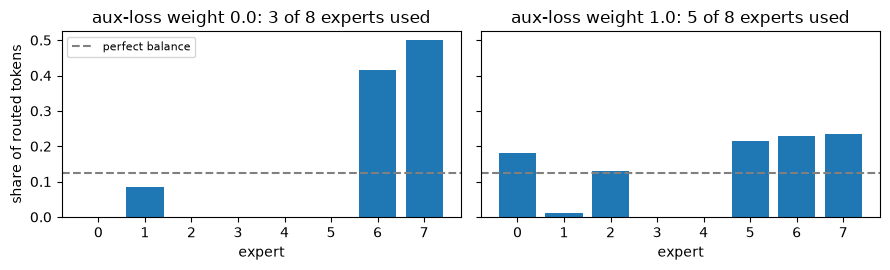

In [17]:
# 🧪 [Added] a minimal router with the Switch-Transformer auxiliary loss
class ToyMoE(nn.Module):
    def __init__(self, d, hidden, n_experts=8, top_k=2):
        super().__init__()
        self.router = nn.Linear(d, n_experts, bias=False)
        self.experts = nn.ModuleList(nn.Sequential(nn.Linear(d, hidden), nn.SiLU(), nn.Linear(hidden, d)) for _ in range(n_experts))
        self.E, self.k = n_experts, top_k
    def forward(self, x):
        h = x.reshape(-1, x.shape[-1])
        probs = F.softmax(self.router(h), dim=-1)
        top_p, top_i = probs.topk(self.k, dim=-1)
        top_p = top_p / top_p.sum(-1, keepdim=True)
        out = torch.zeros_like(h)
        for e in range(self.E):
            tok, slot = (top_i == e).nonzero(as_tuple=True)
            if len(tok):
                out[tok] += top_p[tok, slot, None] * self.experts[e](h[tok])
        frac = F.one_hot(top_i, self.E).float().sum(1).mean(0) / self.k
        self.aux_loss = self.E * (frac * probs.mean(0)).sum()
        self.counts = F.one_hot(top_i, self.E).sum((0, 1))
        return out.view_as(x)

def train_router(aux_weight, steps=300, seed=0):
    torch.manual_seed(seed)
    m = ToyMoE(16, 32)
    opt = torch.optim.Adam(m.parameters(), lr=1e-2)
    target = torch.randn(16, 16)
    for _ in range(steps):
        x = torch.randn(8, 16, 16) + 1.5                 # shifted inputs encourage collapse
        loss = F.mse_loss(m(x), x @ target) + aux_weight * m.aux_loss
        opt.zero_grad(); loss.backward(); opt.step()
    with torch.no_grad():
        m(torch.randn(64, 16, 16) + 1.5)
    return m.counts.float() / m.counts.sum()

fig, axes = plt.subplots(1, 2, figsize=(9, 2.8), sharey=True)
for ax, w in zip(axes, (0.0, 1.0)):
    share = train_router(w)
    ax.bar(range(8), share); ax.axhline(1 / 8, color="gray", ls="--", label="perfect balance")
    ax.set_title(f"aux-loss weight {w}: {(share > 0.02).sum().item()} of 8 experts used"); ax.set_xlabel("expert")
axes[0].set_ylabel("share of routed tokens"); axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

| | Dense | MoE |
|---|---|---|
| Compute (FLOPs) per token | ∝ all parameters | ∝ **activated** parameters |
| GPU memory for weights | ∝ all parameters | ∝ **total** parameters |
| Quality at equal training FLOPs | baseline | usually better |
| Engineering | simple | load balancing, expert parallelism (all-to-all), harder fine-tuning, less efficient at batch size 1 |

## 6. Check yourself (interview-style)

🧪 *[Added]*

<details><summary><b>Q1. Walk me from a GPT-2 block to a Llama 3 block. What changed and why?</b></summary>

Same pre-norm residual decoder. (1) Learned absolute positions → RoPE on Q/K in every layer: relative positions, extendable context. (2) LayerNorm → RMSNorm: no centering or bias, cheaper, equally stable. (3) MHA → GQA: shared K/V heads, 4× smaller KV cache. (4) GELU MLP → SwiGLU: gated FFN, better quality per parameter. (5) No biases or dropout; untied embeddings; 128k vocabulary; larger RoPE base. Most of the quality gain since 2019 came from data and scale — the architecture has largely converged.
</details>

<details><summary><b>Q2. Why pre-norm instead of post-norm?</b></summary>

Pre-norm normalizes each sublayer's input and leaves the residual stream untouched, giving a clean identity path from input to output; gradients do not shrink through many layers and training is stable without long warm-up. Post-norm can reach slightly better quality when it trains but is fragile for deep models.
</details>

<details><summary><b>Q3. Estimate the parameters of Llama 3 8B from its config.</b></summary>

$d=4096$, $L=32$, 32 Q / 8 KV heads, $d_{ff}=14{,}336$, $V=128{,}256$. Attention per layer: $2d^2 + 2\cdot d\cdot1024 ≈ 42$M; SwiGLU $3\cdot4096\cdot14336 ≈ 176$M; ≈ 218M × 32 ≈ 6.98B. Embedding + untied head $2\cdot128256\cdot4096 ≈ 1.05$B. Total ≈ 8.03B, ~70% in the FFNs.
</details>

<details><summary><b>Q4. Explain MoE: what is sparse, total vs activated, and the costs?</b></summary>

The FFN is replaced by $E$ experts plus a router that sends each token to its top-$k$; outputs are a gate-weighted sum (optionally plus always-on shared experts). FLOPs and activations scale with activated parameters, weight memory with total parameters. Benefits: more capacity per FLOP. Costs: all weights in memory, load balancing, expert capacity and token dropping, all-to-all communication, trickier fine-tuning and low-batch efficiency.
</details>

<details><summary><b>Q5. What happens without load balancing?</b></summary>

Router collapse: a few experts get most tokens and gradients and become even more preferred; others stay untrained, capacity is wasted, overloaded experts drop tokens, and expert-parallel GPUs become unevenly loaded. Fixes: auxiliary balancing loss (Switch), capacity factors, or bias-based auxiliary-loss-free balancing (DeepSeek-V3).
</details>

<details><summary><b>Q6. Why does SwiGLU use a hidden size of about 8/3·d instead of 4d?</b></summary>

It has three matrices (gate, up, down) instead of two. With hidden $\tfrac83 d$, $3\cdot d\cdot\tfrac83 d = 8d^2$ equals the two-matrix MLP with hidden $4d$, so comparisons are at equal parameters and FLOPs.
</details>

## References

- Raschka, LLMs-from-scratch: [GPT → Llama 2](https://github.com/rasbt/LLMs-from-scratch/blob/main/ch05/07_gpt_to_llama/converting-gpt-to-llama2.ipynb), [Llama 2 → Llama 3](https://github.com/rasbt/LLMs-from-scratch/blob/main/ch05/07_gpt_to_llama/converting-llama2-to-llama3.ipynb), [MoE bonus](https://github.com/rasbt/LLMs-from-scratch/tree/main/ch04/07_moe) (Apache-2.0); course notebook `03_architecture_gpt.ipynb`.
- Touvron et al. (2023), *Llama 2*, [arXiv:2307.09288](https://arxiv.org/abs/2307.09288); Llama Team (2024), *The Llama 3 Herd of Models*, [arXiv:2407.21783](https://arxiv.org/abs/2407.21783).
- Zhang & Sennrich (2019), *RMSNorm*, [arXiv:1910.07467](https://arxiv.org/abs/1910.07467); Shazeer (2020), *GLU Variants Improve Transformer*, [arXiv:2002.05202](https://arxiv.org/abs/2002.05202).
- Fedus et al. (2021), *Switch Transformers*, [arXiv:2101.03961](https://arxiv.org/abs/2101.03961); Jiang et al. (2024), *Mixtral of Experts*, [arXiv:2401.04088](https://arxiv.org/abs/2401.04088); Dai et al. (2024), *DeepSeekMoE*, [arXiv:2401.06066](https://arxiv.org/abs/2401.06066); DeepSeek-AI (2024), *DeepSeek-V3*, [arXiv:2412.19437](https://arxiv.org/abs/2412.19437).